In [19]:
import numpy as np
import matplotlib.pyplot as plt

In [20]:
with open("output.txt") as file:
    data = file.read()
data = data.replace(" ", "")# remove whitespaces
data = data.replace(";", ",")

line_list = []#each entry corresponds to the data from one model run

for line in data.splitlines():
    if line.startswith('M') or line.startswith('L') or line.startswith('C'):#ignore lines not containing the model run data
        continue

    line_list.append(line)

for i in range(len(line_list)):
    line_list[i] = line_list[i].split(",")#split each line into a list of values
    if line_list[i][-1] == '':#remove empty entries at the end of the list
        line_list[i].pop(-1)

data_array = np.array(line_list, dtype=float)#convert the list of lists into a numpy array

In [21]:
n_timesteps = data_array.shape[0]#number of timesteps in the simulation
nlayers = data_array.shape[1]/4#number of layers in the simulation (each layer has 4 values: id, p, T, theta)
print("Number of timesteps:", n_timesteps, "Number of layers: ", nlayers)

Number of timesteps: 1000 Number of layers:  10.0


In [22]:
def get_data_from_array(layer_id, variable):
    """
    Returns the data for a specific layer and variable from the data_array.
    
    Parameters:
    layer_id (int): The ID of the layer (0-indexed).
    variable (str): The variable to retrieve ('p', 'T', or 'theta').
    
    Returns:
    np.ndarray: The data for the specified layer and variable.
    """
    if variable == 'p':
        return data_array[:, layer_id * 4 + 1]
    elif variable == 'theta':
        return data_array[:, layer_id * 4 + 2]
    elif variable == 'T':
        return data_array[:, layer_id * 4 + 3]
    else:
        raise ValueError("Variable must be one of 'p', 'T', or 'theta'.")

In [23]:
temps = get_data_from_array(8,'T')

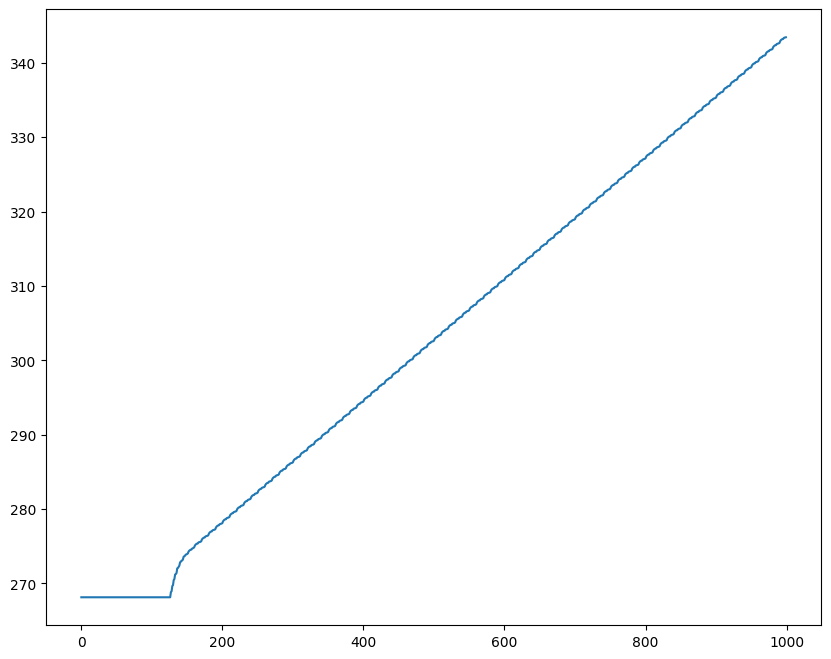

In [24]:
plt.figure(figsize=(10, 8))
plt.plot(range(n_timesteps), temps)